In [13]:
###Import Libraries###
import os
import urllib.request
from pathlib import Path
from datetime import datetime
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
import seaborn as sns
import sqlite3

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
###Directory Paths###
KNOWN_DIR = "known_faces" ##use atleast 20-30 images per person
EVAL_DIR = "evaluation" ##use at least 5 images per person
TEST_DIR = "test_images"
OUTPUT_DIR = "output"
MODEL_DIR = "models"

EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
COSINE_THRESHOLD = 0.36 ##used different values; advised between 0.3-0.5.

for folder in [KNOWN_DIR, EVAL_DIR, TEST_DIR, OUTPUT_DIR, MODEL_DIR]:
    os.makedirs(folder, exist_ok=True)

In [3]:
TEST_DIR = Path(TEST_DIR)
OUTPUT_DIR = Path(OUTPUT_DIR)

print("Test directory:", TEST_DIR.resolve())
print("Output directory:", OUTPUT_DIR.resolve())

Test directory: /home/vamika/Desktop/ImageProcessing/lfw_dataset/test_images
Output directory: /home/vamika/Desktop/ImageProcessing/lfw_dataset/output


In [4]:
###Download YuNET and SFace###
models = {
    "face_detection_yunet_2023mar.onnx":
        "https://huggingface.co/opencv/face_detection_yunet/resolve/main/face_detection_yunet_2023mar.onnx",
    "face_recognition_sface_2021dec.onnx":
        "https://huggingface.co/opencv/face_recognition_sface/resolve/main/face_recognition_sface_2021dec.onnx"
}

for filename, url in models.items():
    path = os.path.join(MODEL_DIR, filename)
    if not os.path.exists(path) or os.path.getsize(path) == 0:
        print("Downloading:", filename)
        urllib.request.urlretrieve(url, path)

YUNET = os.path.join(MODEL_DIR, "face_detection_yunet_2023mar.onnx")
SFACE = os.path.join(MODEL_DIR, "face_recognition_sface_2021dec.onnx")

detector = cv2.FaceDetectorYN.create(
    YUNET, "", (320, 320), 0.85, 0.30, 5000
)
recognizer = cv2.FaceRecognizerSF.create(SFACE, "")

print("OpenCV:", cv2.__version__)
print("Detector initialized:", detector is not None)
print("Recognizer initialized:", recognizer is not None)

OpenCV: 5.0.0
Detector initialized: True
Recognizer initialized: True


[ WARN:0@2.135] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now
[ WARN:0@2.230] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


In [5]:
###Helper Functions###
def list_images(folder):
    return sorted(
        str(p) for p in Path(folder).rglob("*")
        if p.is_file() and p.suffix.lower() in EXTS
    )

def detect_faces(image):
    if image is None:
        return None
    h, w = image.shape[:2]
    detector.setInputSize((w, h))
    return detector.detect(image)[1]

def largest_face(faces):
    if faces is None or len(faces) == 0:
        return None
    return max(faces, key=lambda f: float(f[2] * f[3]))

def get_embedding(image, face):
    aligned = recognizer.alignCrop(image, face)
    return recognizer.feature(aligned)

,Person,Path,Read_OK,Width,Height,Brightness,Faces_Detected
0,Alejandro_Toledo,known_faces/Alejandro_Toledo/Alejandro_Toledo_...,True,250,250,110.229872,1
1,Alejandro_Toledo,known_faces/Alejandro_Toledo/Alejandro_Toledo_...,True,250,250,102.436080,1
2,Alejandro_Toledo,known_faces/Alejandro_Toledo/Alejandro_Toledo_...,True,250,250,95.165152,1
3,Alejandro_Toledo,known_faces/Alejandro_Toledo/Alejandro_Toledo_...,True,250,250,85.108528,1
4,Alejandro_Toledo,known_faces/Alejandro_Toledo/Alejandro_Toledo_...,True,250,250,103.334832,1
...,...,...,...,...,...,...,...
2230,Vladimir_Putin,known_faces/Vladimir_Putin/Vladimir_Putin_0045...,True,250,250,97.978560,1
2231,Vladimir_Putin,known_faces/Vladimir_Putin/Vladimir_Putin_0046...,True,250,250,70.255056,1
2232,Vladimir_Putin,known_faces/Vladimir_Putin/Vladimir_Putin_0047...,True,250,250,110.281392,1
2233,Vladimir_Putin,known_faces/Vladimir_Putin/Vladimir_Putin_0048...,True,250,250,149.227440,1


,Image_Count
Person,
Alejandro_Toledo,39
Alvaro_Uribe,35
Andre_Agassi,36
Ariel_Sharon,77
Arnold_Schwarzenegger,42
Colin_Powell,236
Donald_Rumsfeld,121
George_W_Bush,530
Gerhard_Schroeder,109


,Width,Height,Brightness,Faces_Detected
count,2235.0,2235.0,2235.000000,2235.000000
mean,250.0,250.0,99.067518,1.132438
std,0.0,0.0,26.874722,0.390577
min,250.0,250.0,27.214112,1.000000
25%,250.0,250.0,79.810376,1.000000
50%,250.0,250.0,96.594160,1.000000
75%,250.0,250.0,117.242560,1.000000
max,250.0,250.0,190.231680,4.000000


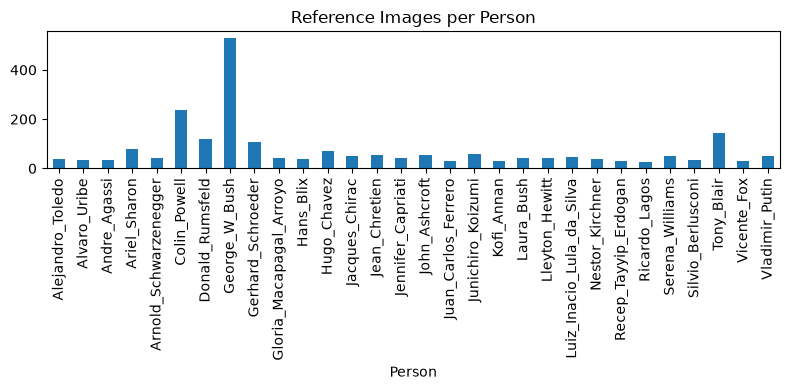

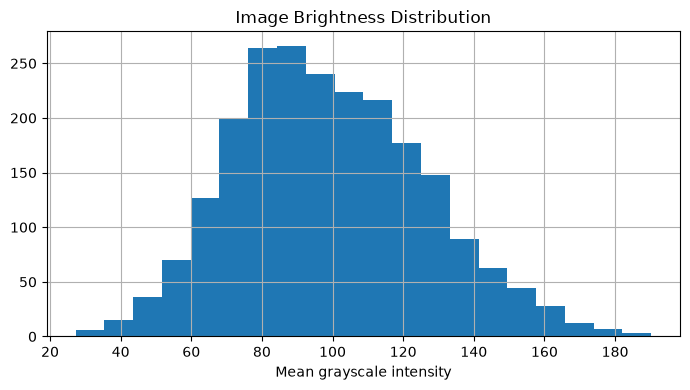

In [6]:
###EDA###
eda_rows = []

for person_dir in sorted(Path(KNOWN_DIR).iterdir()):
    if not person_dir.is_dir():
        continue

    for path in list_images(person_dir):
        image = cv2.imread(path)

        if image is None:
            eda_rows.append({
                "Person": person_dir.name,
                "Path": path,
                "Read_OK": False,
                "Width": np.nan,
                "Height": np.nan,
                "Brightness": np.nan,
                "Faces_Detected": 0
            })
            continue

        h, w = image.shape[:2]
        faces = detect_faces(image)

        eda_rows.append({
            "Person": person_dir.name,
            "Path": path,
            "Read_OK": True,
            "Width": w,
            "Height": h,
            "Brightness": cv2.cvtColor(
                image, cv2.COLOR_BGR2GRAY
            ).mean(),
            "Faces_Detected": 0 if faces is None else len(faces)
        })

eda_df = pd.DataFrame(eda_rows)

if eda_df.empty:
    raise RuntimeError(
        "No reference images found in known_faces/<person>/."
    )

display(eda_df)
display(eda_df.groupby("Person").size().rename("Image_Count").to_frame())
display(eda_df[["Width", "Height", "Brightness",
                "Faces_Detected"]].describe())

eda_df.to_csv(f"{OUTPUT_DIR}/eda_results.csv", index=False)

eda_df.groupby("Person").size().plot(
    kind="bar", title="Reference Images per Person", figsize=(8, 4)
)
plt.tight_layout()
plt.show()

eda_df["Brightness"].dropna().hist(bins=20, figsize=(7, 4))
plt.title("Image Brightness Distribution")
plt.xlabel("Mean grayscale intensity")
plt.tight_layout()
plt.show()

In [7]:
###Embeddings###
known_features, known_names = [], []
failures = []

for person_dir in sorted(Path(KNOWN_DIR).iterdir()):
    if not person_dir.is_dir():
        continue

    for path in list_images(person_dir):
        image = cv2.imread(path)

        if image is None:
            failures.append({"Path": path, "Reason": "Unreadable"})
            continue

        face = largest_face(detect_faces(image))

        if face is None:
            failures.append({"Path": path, "Reason": "No face detected"})
            continue

        try:
            known_features.append(get_embedding(image, face))
            known_names.append(person_dir.name)
        except Exception as e:
            failures.append({"Path": path, "Reason": str(e)})

if not known_features:
    raise RuntimeError("No usable reference embeddings were created.")

pd.DataFrame(failures).to_csv(
    f"{OUTPUT_DIR}/embedding_failures.csv", index=False
)

print("Usable reference embeddings:", len(known_features))
display(pd.Series(known_names, name="Person").value_counts())

Usable reference embeddings: 2235


Person
George_W_Bush                530
Colin_Powell                 236
Tony_Blair                   144
Donald_Rumsfeld              121
Gerhard_Schroeder            109
Ariel_Sharon                  77
Hugo_Chavez                   71
Junichiro_Koizumi             60
Jean_Chretien                 55
John_Ashcroft                 53
Jacques_Chirac                52
Serena_Williams               52
Vladimir_Putin                49
Luiz_Inacio_Lula_da_Silva     48
Gloria_Macapagal_Arroyo       44
Arnold_Schwarzenegger         42
Jennifer_Capriati             42
Laura_Bush                    41
Lleyton_Hewitt                41
Alejandro_Toledo              39
Hans_Blix                     39
Nestor_Kirchner               37
Andre_Agassi                  36
Alvaro_Uribe                  35
Silvio_Berlusconi             33
Kofi_Annan                    32
Vicente_Fox                   32
Recep_Tayyip_Erdogan          30
Juan_Carlos_Ferrero           28
Ricardo_Lagos                 27
Nam

In [8]:
###For Recognition###
def best_match(image, face):
    query = get_embedding(image, face)
    scores = [
        float(recognizer.match(
            query, feature, cv2.FaceRecognizerSF_FR_COSINE
        ))
        for feature in known_features
    ]

    idx = int(np.argmax(scores))
    return known_names[idx], scores[idx]

def apply_threshold(candidate, score, threshold=COSINE_THRESHOLD):
    return candidate if score >= threshold else "UNKNOWN"

In [9]:
def process_test_image(image_path):
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Could not read image: {image_path}")

    height, width = image.shape[:2]
    detector.setInputSize((width, height))

    _, faces = detector.detect(image)
    results = []

    if faces is None or len(faces) == 0:
        return pd.DataFrame(columns=["Name", "Similarity"])

    for face in faces:
        aligned_face = recognizer.alignCrop(image, face)
        feature = recognizer.feature(aligned_face)

        best_name = "Unknown"
        best_similarity = -1.0

        # Comparison with all known reference embeddings
        for known_name, known_feature in zip(
            known_names, known_features
        ):
            similarity = recognizer.match(
                feature,
                known_feature,
                cv2.FaceRecognizerSF_FR_COSINE
            )

            if similarity > best_similarity:
                best_similarity = similarity
                best_name = known_name

        # Apply recognition threshold
        if best_similarity < COSINE_THRESHOLD:
            best_name = "Unknown"

        results.append({
            "Name": best_name,
            "Similarity": float(best_similarity)
        })

    return pd.DataFrame(results)

In [10]:
###Run recognition on Test files###
def get_actual_name(image_path):
    filename = Path(image_path).stem

    # Remove Jupyter checkpoint suffix
    filename = re.sub(r"-checkpoint$", "", filename)

    # Remove final numeric image identifier
    filename = re.sub(r"_\d+$", "", filename)

    return filename.strip()

test_files = [
    Path(p) for p in list_images(TEST_DIR)
    if ".ipynb_checkpoints" not in Path(p).parts
    and "-checkpoint" not in Path(p).stem
]

print("Test directory:", TEST_DIR.resolve())
print("Output directory:", OUTPUT_DIR.resolve())
print("Number of test images:", len(test_files))

if not test_files:
    raise ValueError(
        f"No valid test images found in {TEST_DIR.resolve()}"
    )
results = []

for image_path in test_files:

    true_name = get_actual_name(image_path)

    try:
        detections = process_test_image(str(image_path))

        if detections is None or detections.empty:
            predicted_name = "UNKNOWN"
            similarity = np.nan

        else:
            # Highest similarity detection
            best = detections.loc[
                detections["Similarity"].idxmax()
            ]

            predicted_name = str(best["Name"]).strip()
            similarity = float(best["Similarity"])

    except Exception as e:
        print(f"Error processing {image_path.name}: {e}")

        predicted_name = "UNKNOWN"
        similarity = np.nan

    results.append({
        "Image": image_path.name,
        "True": true_name,
        "Predicted": predicted_name,
        "Similarity": similarity
    })

Test directory: /home/vamika/Desktop/ImageProcessing/lfw_dataset/test_images
Output directory: /home/vamika/Desktop/ImageProcessing/lfw_dataset/output
Number of test images: 10


In [17]:
###Save prediction and calculate Metrics###

test_results = pd.DataFrame(results)


true = test_results["True"].str.strip().str.casefold().to_numpy()
pred = (
    test_results["Predicted"]
    .str.strip()
    .str.casefold()
    .to_numpy()
)


reject_labels = {"unknown", "no_face", "no face"}
known = ~np.isin(true, list(reject_labels))
unknown = ~known
pred_rejected = np.isin(pred, list(reject_labels))

correct = true == pred

test_results["Correct"] = correct

test_results.to_csv(
    OUTPUT_DIR / "test_prediction_results.csv",
    index=False
)

print("\n========== TEST PREDICTIONS ==========")
display(test_results)

accuracy = accuracy_score(true, pred)

balanced_acc = balanced_accuracy_score(true, pred)

macro_precision = precision_score(
    true, pred, average="macro", zero_division=0
)
macro_recall = recall_score(
    true, pred, average="macro", zero_division=0
)
macro_f1 = f1_score(
    true, pred, average="macro", zero_division=0
)

weighted_precision = precision_score(
    true, pred, average="weighted", zero_division=0
)
weighted_recall = recall_score(
    true, pred, average="weighted", zero_division=0
)
weighted_f1 = f1_score(
    true, pred, average="weighted", zero_division=0
)

micro_precision = precision_score(
    true, pred, average="micro", zero_division=0
)
micro_recall = recall_score(
    true, pred, average="micro", zero_division=0
)
micro_f1 = f1_score(
    true, pred, average="micro", zero_division=0
)

false_rejections = known & pred_rejected
wrong_identity = known & ~pred_rejected & (true != pred)
unknown_false_accept = unknown & ~pred_rejected

frr = (
    false_rejections.sum() / known.sum()
    if known.sum() else np.nan
)

wrong_identity_rate = (
    wrong_identity.sum() / known.sum()
    if known.sum() else np.nan
)

far = (
    unknown_false_accept.sum() / unknown.sum()
    if unknown.sum() else np.nan
)

metrics = pd.DataFrame([
    ("Total test images", len(test_results)),
    ("Correct predictions", int(correct.sum())),
    ("Incorrect predictions", int((~correct).sum())),
    ("Accuracy (%)", accuracy * 100),
    ("Balanced accuracy (%)", balanced_acc * 100),
    ("Macro precision (%)", macro_precision * 100),
    ("Macro recall (%)", macro_recall * 100),
    ("Macro F1-score (%)", macro_f1 * 100),
    ("Weighted precision (%)", weighted_precision * 100),
    ("Weighted recall (%)", weighted_recall * 100),
    ("Weighted F1-score (%)", weighted_f1 * 100),
    ("Micro precision (%)", micro_precision * 100),
    ("Micro recall (%)", micro_recall * 100),
    ("Micro F1-score (%)", micro_f1 * 100),
    ("Known images", int(known.sum())),
    ("False rejections", int(false_rejections.sum())),
    ("False rejection rate (%)", frr * 100),
    ("Wrong known identities", int(wrong_identity.sum())),
    ("Wrong identity rate among known (%)",
     wrong_identity_rate * 100),
    ("Unknown images", int(unknown.sum())),
    ("Unknown accepted as known",
     int(unknown_false_accept.sum())),
    ("Unknown false acceptance rate (%)", far * 100)
], columns=["Metric", "Value"])

metrics.to_csv(
    OUTPUT_DIR / "test_metrics.csv",
    index=False
)

print("\n========== OVERALL TEST METRICS ==========")
display(metrics)


========== TEST PREDICTIONS ==========


,Image,True,Predicted,Similarity,Correct
0,Adam_Herbert_0001.jpg,Adam_Herbert,Unknown,0.261883,False
1,Ariel_Sharon_0004.jpg,Ariel_Sharon,Ariel_Sharon,1.000000,True
2,George_W_Bush_0006.jpg,George_W_Bush,George_W_Bush,1.000000,True
3,Jonathan_Fine_0001.jpg,Jonathan_Fine,Andre_Agassi,0.462920,False
4,Luis_Sanchez_0001.jpg,Luis_Sanchez,Unknown,0.291663,False
5,Ricardo_Lagos_0013.jpg,Ricardo_Lagos,Ricardo_Lagos,1.000000,True
6,Serena_Williams_0008.jpg,Serena_Williams,Serena_Williams,1.000000,True
7,Vladimir_Putin_0003.jpg,Vladimir_Putin,Vladimir_Putin,1.000000,True
8,Wen_Ho_Lee_0001.jpg,Wen_Ho_Lee,Colin_Powell,0.383598,False
9,Yuvraj_Singh_0001.jpg,Yuvraj_Singh,Unknown,0.334162,False



========== OVERALL TEST METRICS ==========


/home/vamika/miniconda3/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,Metric,Value
0,Total test images,10.000000
1,Correct predictions,5.000000
2,Incorrect predictions,5.000000
3,Accuracy (%),50.000000
4,Balanced accuracy (%),50.000000
5,Macro precision (%),38.461538
6,Macro recall (%),38.461538
7,Macro F1-score (%),38.461538
8,Weighted precision (%),50.000000
9,Weighted recall (%),50.000000


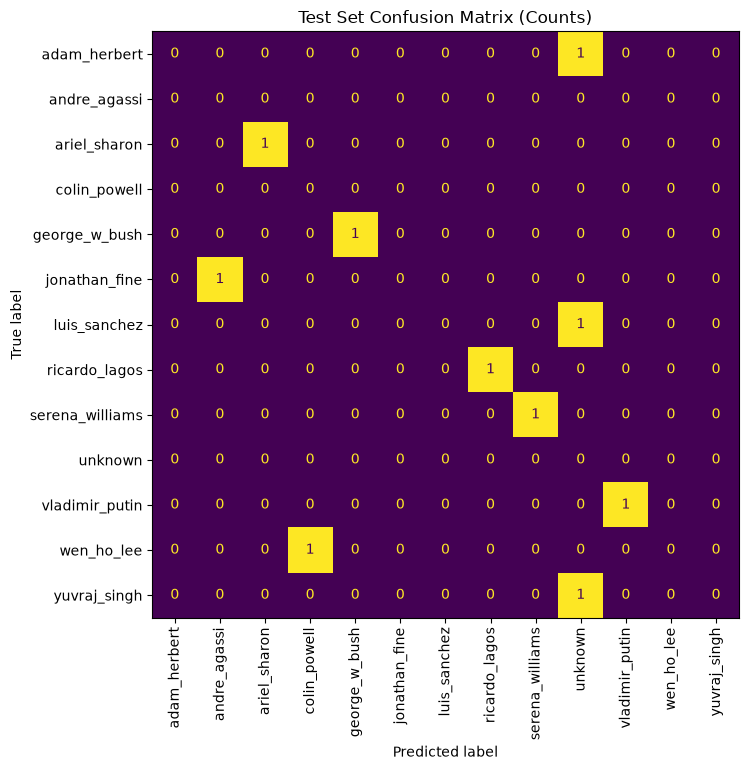

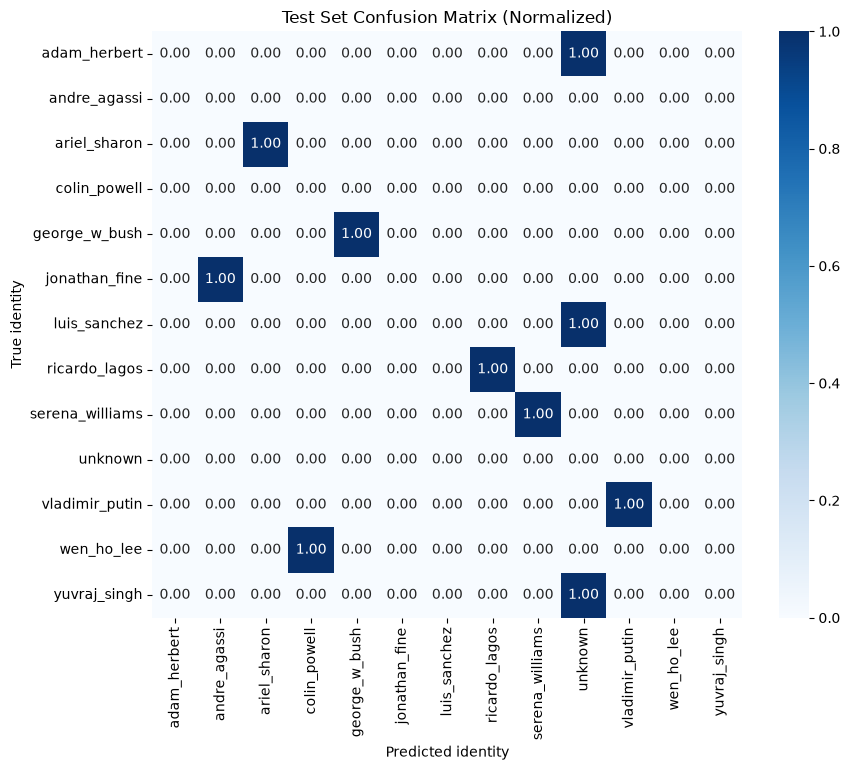


========== PER-PERSON ACCURACY ==========


,Total_Images,Correct_Count,Accuracy,Accuracy_Percent
True,,,,
Adam_Herbert,1,0,0.0,0.0
Ariel_Sharon,1,1,1.0,100.0
George_W_Bush,1,1,1.0,100.0
Jonathan_Fine,1,0,0.0,0.0
Luis_Sanchez,1,0,0.0,0.0
Ricardo_Lagos,1,1,1.0,100.0
Serena_Williams,1,1,1.0,100.0
Vladimir_Putin,1,1,1.0,100.0
Wen_Ho_Lee,1,0,0.0,0.0


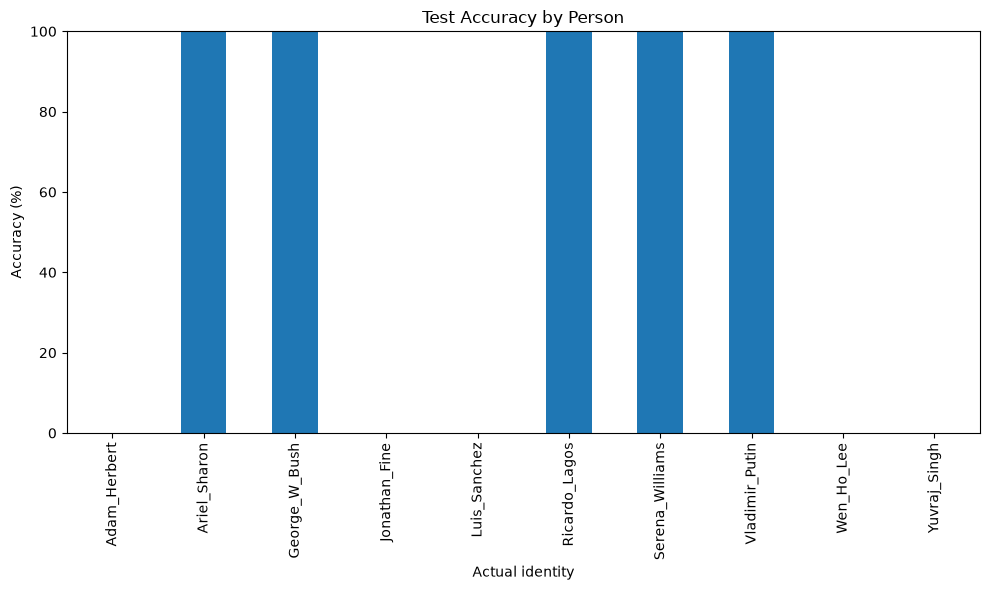

,Identity,Images,Correct,Accuracy,Precision,Recall,F1_Score
0,adam_herbert,1,0,0.0,0.0,0.0,0.0
1,ariel_sharon,1,1,1.0,1.0,1.0,1.0
2,george_w_bush,1,1,1.0,1.0,1.0,1.0
3,jonathan_fine,1,0,0.0,0.0,0.0,0.0
4,luis_sanchez,1,0,0.0,0.0,0.0,0.0
5,ricardo_lagos,1,1,1.0,1.0,1.0,1.0
6,serena_williams,1,1,1.0,1.0,1.0,1.0
7,vladimir_putin,1,1,1.0,1.0,1.0,1.0
8,wen_ho_lee,1,0,0.0,0.0,0.0,0.0
9,yuvraj_singh,1,0,0.0,0.0,0.0,0.0


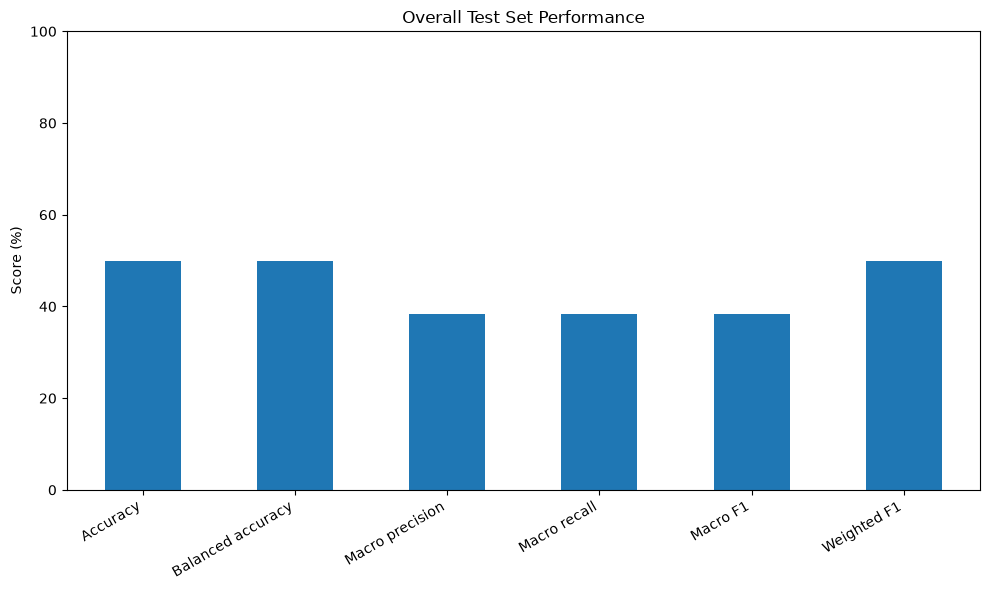

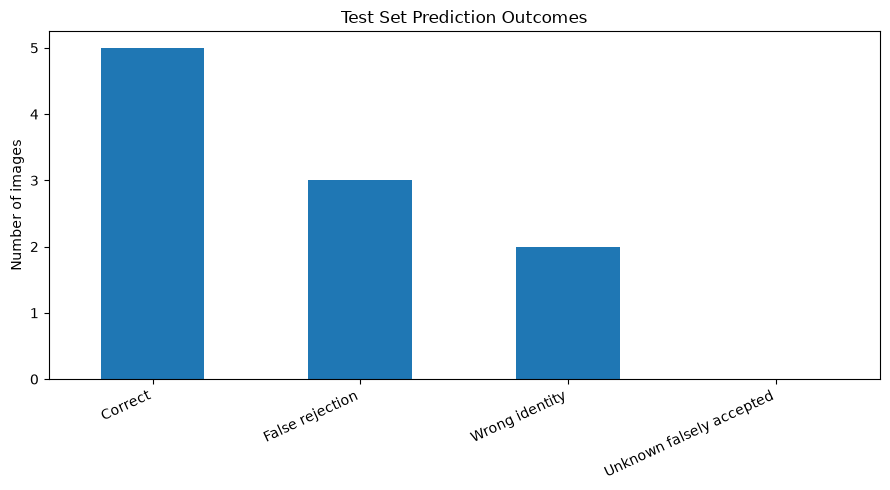

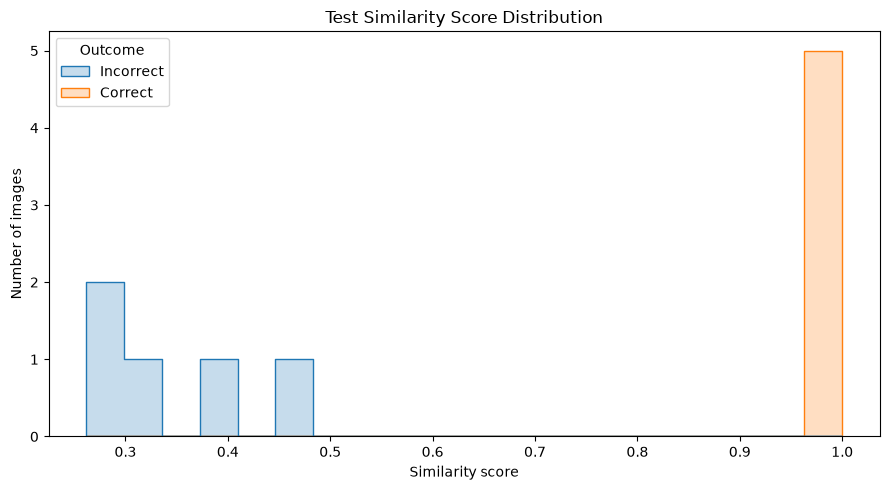


========== MISCLASSIFIED IMAGES ==========


,Image,True,Predicted,Similarity,Correct
0,Adam_Herbert_0001.jpg,Adam_Herbert,Unknown,0.261883,False
3,Jonathan_Fine_0001.jpg,Jonathan_Fine,Andre_Agassi,0.462920,False
4,Luis_Sanchez_0001.jpg,Luis_Sanchez,Unknown,0.291663,False
8,Wen_Ho_Lee_0001.jpg,Wen_Ho_Lee,Colin_Powell,0.383598,False
9,Yuvraj_Singh_0001.jpg,Yuvraj_Singh,Unknown,0.334162,False



========== FINAL SUMMARY ==========
Test images       : 10
Correct           : 5
Incorrect         : 5
Accuracy          : 50.00%
Macro F1-score    : 0.3846
Weighted F1-score : 0.5000
Balanced accuracy : 50.00%

All results saved in:
/home/vamika/Desktop/ImageProcessing/lfw_dataset/output

Generated test files:
test_confusion_matrix.csv
test_confusion_matrix.png
test_confusion_matrix_normalized.png
test_images
test_metrics.csv
test_misclassified_images.csv
test_overall_metrics.png
test_per_person_accuracy.csv
test_per_person_accuracy.png
test_per_person_metrics.csv
test_prediction_outcomes.png
test_prediction_results.csv
test_similarity_distribution.png


In [18]:
###Confusion Matrix, Metrics Plot, Overall Summary###

labels = sorted(set(true) | set(pred))

cm = confusion_matrix(
    true,
    pred,
    labels=labels
)

cm_df = pd.DataFrame(
    cm,
    index=labels,
    columns=labels
)

cm_df.index.name = "True identity"
cm_df.columns.name = "Predicted identity"

cm_df.to_csv(
    OUTPUT_DIR / "test_confusion_matrix.csv"
)

fig, ax = plt.subplots(
    figsize=(
        max(9, len(labels) * 0.7),
        max(7, len(labels) * 0.6)
    )
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
).plot(
    ax=ax,
    xticks_rotation=90,
    colorbar=False,
    values_format="d"
)

ax.set_title("Test Set Confusion Matrix (Counts)")
plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)




row_totals = cm.sum(axis=1, keepdims=True)

cm_normalized = np.divide(
    cm,
    row_totals,
    out=np.zeros_like(cm, dtype=float),
    where=row_totals != 0
)

fig, ax = plt.subplots(
    figsize=(
        max(9, len(labels) * 0.7),
        max(7, len(labels) * 0.6)
    )
)

sns.heatmap(
    cm_normalized,
    annot=len(labels) <= 20,
    fmt=".2f",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    vmin=0,
    vmax=1,
    ax=ax
)

ax.set_title("Test Set Confusion Matrix (Normalized)")
ax.set_xlabel("Predicted identity")
ax.set_ylabel("True identity")

plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "test_confusion_matrix_normalized.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)




per_person = test_results.groupby("True").agg(
    Total_Images=("Correct", "count"),
    Correct_Count=("Correct", "sum"),
    Accuracy=("Correct", "mean")
)

per_person["Accuracy_Percent"] = (
    per_person["Accuracy"] * 100
)

per_person.to_csv(
    OUTPUT_DIR / "test_per_person_accuracy.csv"
)

print("\n========== PER-PERSON ACCURACY ==========")
display(per_person)

fig, ax = plt.subplots(
    figsize=(max(10, len(per_person) * 0.6), 6)
)

per_person["Accuracy_Percent"].plot(
    kind="bar",
    ax=ax
)

ax.set_title("Test Accuracy by Person")
ax.set_xlabel("Actual identity")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 100)

plt.xticks(rotation=90)
plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "test_per_person_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)




summary_rows = []

for person in sorted(set(true)):
    mask = true == person

    person_true = true[mask]
    person_pred = pred[mask]

    summary_rows.append({
        "Identity": person,
        "Images": int(mask.sum()),
        "Correct": int((person_true == person_pred).sum()),
        "Accuracy": accuracy_score(person_true, person_pred),
        "Precision": precision_score(
            person_true, person_pred,
            labels=[person],
            average="micro",
            zero_division=0
        ),
        "Recall": recall_score(
            person_true, person_pred,
            labels=[person],
            average="micro",
            zero_division=0
        ),
        "F1_Score": f1_score(
            person_true, person_pred,
            labels=[person],
            average="micro",
            zero_division=0
        )
    })

per_person_metrics = pd.DataFrame(summary_rows)

per_person_metrics.to_csv(
    OUTPUT_DIR / "test_per_person_metrics.csv",
    index=False
)

display(per_person_metrics)




metric_plot = pd.Series({
    "Accuracy": accuracy * 100,
    "Balanced accuracy": balanced_acc * 100,
    "Macro precision": macro_precision * 100,
    "Macro recall": macro_recall * 100,
    "Macro F1": macro_f1 * 100,
    "Weighted F1": weighted_f1 * 100
})

fig, ax = plt.subplots(figsize=(10, 6))

metric_plot.plot(kind="bar", ax=ax)

ax.set_title("Overall Test Set Performance")
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 100)

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "test_overall_metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)




outcomes = pd.Series({
    "Correct": int(correct.sum()),
    "False rejection": int(false_rejections.sum()),
    "Wrong identity": int(wrong_identity.sum()),
    "Unknown falsely accepted": int(unknown_false_accept.sum())
})

fig, ax = plt.subplots(figsize=(9, 5))

outcomes.plot(kind="bar", ax=ax)

ax.set_title("Test Set Prediction Outcomes")
ax.set_ylabel("Number of images")

plt.xticks(rotation=25, ha="right")
plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "test_prediction_outcomes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)




score_data = test_results.dropna(
    subset=["Similarity"]
).copy()

if not score_data.empty:

    score_data["Outcome"] = np.where(
        score_data["Correct"],
        "Correct",
        "Incorrect"
    )

    fig, ax = plt.subplots(figsize=(9, 5))

    sns.histplot(
        data=score_data,
        x="Similarity",
        hue="Outcome",
        bins=20,
        element="step",
        ax=ax
    )

    ax.set_title("Test Similarity Score Distribution")
    ax.set_xlabel("Similarity score")
    ax.set_ylabel("Number of images")

    plt.tight_layout()

    fig.savefig(
        OUTPUT_DIR / "test_similarity_distribution.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)



mismatches = test_results.loc[
    ~test_results["Correct"]
].copy()

mismatches.to_csv(
    OUTPUT_DIR / "test_misclassified_images.csv",
    index=False
)

print("\n========== MISCLASSIFIED IMAGES ==========")
display(mismatches)



print("\n========== FINAL SUMMARY ==========")
print(f"Test images       : {len(test_results)}")
print(f"Correct           : {int(correct.sum())}")
print(f"Incorrect         : {int((~correct).sum())}")
print(f"Accuracy          : {accuracy * 100:.2f}%")
print(f"Macro F1-score    : {macro_f1:.4f}")
print(f"Weighted F1-score : {weighted_f1:.4f}")
print(f"Balanced accuracy : {balanced_acc * 100:.2f}%")

print("\nAll results saved in:")
print(OUTPUT_DIR.resolve())

print("\nGenerated test files:")
for file_path in sorted(OUTPUT_DIR.glob("test_*")):
    print(file_path.name)

In [11]:
# Generate attendance using TEST_DIR as a csv file
test_files = list_images(TEST_DIR)
attendance_results = []

print("Test images found:", len(test_files))

for image_path in test_files:
    image_path = Path(image_path)

    try:
        detections = process_test_image(str(image_path))

        if not detections.empty:
            best = detections.loc[detections["Similarity"].idxmax()]
            predicted_name = str(best["Name"]).strip()

            if predicted_name.casefold() not in ["unknown", "no_face", ""]:
                now = datetime.now()

                attendance_results.append({
                    "Image": image_path.name,
                    "Name": predicted_name,
                    "Date": now.strftime("%Y-%m-%d"),
                    "Time": now.strftime("%H:%M:%S"),
                    "Similarity": best["Similarity"],
                    "Status": "Present"
                })

    except Exception as e:
        print(f"Error processing {image_path.name}: {e}")

# Create attendance table
attendance = pd.DataFrame(
    attendance_results,
    columns=["Image", "Name", "Date", "Time", "Similarity", "Status"]
)

if not attendance.empty:
    # Keep one entry per recognized person, retaining the highest similarity
    attendance = attendance.sort_values(
        "Similarity", ascending=False
    )

    attendance = attendance.drop_duplicates(
        subset=["Name"], keep="first"
    ).reset_index(drop=True)

    print("\nAttendance Summary")
    print("People present:", len(attendance))

    display(attendance)

    # Save report inside OUTPUT_DIR
    OUTPUT_DIR = Path(OUTPUT_DIR)
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    attendance_path = OUTPUT_DIR / "attendance.csv"
    attendance.to_csv(attendance_path, index=False)

    print(f"\nAttendance saved to: {attendance_path}")

else:
    print("No recognized faces found. Attendance not generated.")


Test images found: 15

Attendance Summary
People present: 7


,Image,Name,Date,Time,Similarity,Status
0,Ariel_Sharon_0004.jpg,Ariel_Sharon,2026-10-29,18:09:12,1.000000,Present
1,George_W_Bush_0006.jpg,George_W_Bush,2026-10-29,18:09:12,1.000000,Present
2,Ricardo_Lagos_0013.jpg,Ricardo_Lagos,2026-10-29,18:09:12,1.000000,Present
3,Vladimir_Putin_0003.jpg,Vladimir_Putin,2026-10-29,18:09:12,1.000000,Present
4,Serena_Williams_0008.jpg,Serena_Williams,2026-10-29,18:09:12,1.000000,Present
5,Jonathan_Fine_0001-checkpoint.jpg,Andre_Agassi,2026-10-29,18:09:11,0.462920,Present
6,Wen_Ho_Lee_0001-checkpoint.jpg,Colin_Powell,2026-10-29,18:09:12,0.383598,Present



Attendance saved to: output/attendance.csv


In [14]:
###Generate attendace as an SQL database
test_files = list_images(TEST_DIR)
attendance_results = []

print("Test images found:", len(test_files))

for image_path in test_files:
    image_path = Path(image_path)

    try:
        detections = process_test_image(str(image_path))

        if not detections.empty:
            best = detections.loc[detections["Similarity"].idxmax()]
            predicted_name = str(best["Name"]).strip()

            if predicted_name.casefold() not in ["unknown", "no_face", ""]:
                now = datetime.now()

                attendance_results.append({
                    "Image": image_path.name,
                    "Name": predicted_name,
                    "Date": now.strftime("%Y-%m-%d"),
                    "Time": now.strftime("%H:%M:%S"),
                    "Similarity": float(best["Similarity"]),
                    "Status": "Present"
                })

    except Exception as e:
        print(f"Error processing {image_path.name}: {e}")


# Create attendance DataFrame
attendance = pd.DataFrame(
    attendance_results,
    columns=["Image", "Name", "Date", "Time", "Similarity", "Status"]
)

if not attendance.empty:

    # Retain the highest similarity match for each person
    attendance = attendance.sort_values(
        "Similarity", ascending=False
    )

    attendance = attendance.drop_duplicates(
        subset=["Name"], keep="first"
    ).reset_index(drop=True)

    print("\nAttendance Summary")
    print("People present:", len(attendance))

    display(attendance)


    # SQLite database path
    db_path = OUTPUT_DIR / "attendance.db"

    # Connect to SQLite database
    conn = sqlite3.connect(db_path)
    cursor = conn.cursor()

    # Create attendance table
    cursor.execute("""
        CREATE TABLE IF NOT EXISTS attendance (
            id INTEGER PRIMARY KEY AUTOINCREMENT,
            image TEXT,
            name TEXT,
            date TEXT,
            time TEXT,
            similarity REAL,
            status TEXT
        )
    """)

    # Insert attendance records
    cursor.executemany("""
        INSERT INTO attendance
        (image, name, date, time, similarity, status)
        VALUES (?, ?, ?, ?, ?, ?)
    """, attendance[
        ["Image", "Name", "Date", "Time", "Similarity", "Status"]
    ].itertuples(index=False, name=None))

    conn.commit()

    print("\nAttendance saved successfully!")
    print("Database:", db_path)

    # Display records stored in SQL
    saved_attendance = pd.read_sql_query(
        "SELECT * FROM attendance ORDER BY id DESC",
        conn
    )

    print("\nRecords in SQL Database:")
    display(saved_attendance)

    conn.close()

else:
    print("No recognized faces found. Attendance not generated.")


Test images found: 15

Attendance Summary
People present: 7


,Image,Name,Date,Time,Similarity,Status
0,Ariel_Sharon_0004.jpg,Ariel_Sharon,2026-10-30,12:50:47,1.000000,Present
1,George_W_Bush_0006.jpg,George_W_Bush,2026-10-30,12:50:47,1.000000,Present
2,Ricardo_Lagos_0013.jpg,Ricardo_Lagos,2026-10-30,12:50:47,1.000000,Present
3,Vladimir_Putin_0003.jpg,Vladimir_Putin,2026-10-30,12:50:47,1.000000,Present
4,Serena_Williams_0008.jpg,Serena_Williams,2026-10-30,12:50:47,1.000000,Present
5,Jonathan_Fine_0001-checkpoint.jpg,Andre_Agassi,2026-10-30,12:50:47,0.462920,Present
6,Wen_Ho_Lee_0001-checkpoint.jpg,Colin_Powell,2026-10-30,12:50:47,0.383598,Present



Attendance saved successfully!
Database: output/attendance.db

Records in SQL Database:


,id,image,name,date,time,similarity,status
0,14,Wen_Ho_Lee_0001-checkpoint.jpg,Colin_Powell,2026-10-30,12:50:47,0.383598,Present
1,13,Jonathan_Fine_0001-checkpoint.jpg,Andre_Agassi,2026-10-30,12:50:47,0.462920,Present
2,12,Serena_Williams_0008.jpg,Serena_Williams,2026-10-30,12:50:47,1.000000,Present
3,11,Vladimir_Putin_0003.jpg,Vladimir_Putin,2026-10-30,12:50:47,1.000000,Present
4,10,Ricardo_Lagos_0013.jpg,Ricardo_Lagos,2026-10-30,12:50:47,1.000000,Present
5,9,George_W_Bush_0006.jpg,George_W_Bush,2026-10-30,12:50:47,1.000000,Present
6,8,Ariel_Sharon_0004.jpg,Ariel_Sharon,2026-10-30,12:50:47,1.000000,Present
7,7,Wen_Ho_Lee_0001-checkpoint.jpg,Colin_Powell,2026-10-30,12:47:58,0.383598,Present
8,6,Jonathan_Fine_0001-checkpoint.jpg,Andre_Agassi,2026-10-30,12:47:58,0.462920,Present
9,5,Serena_Williams_0008.jpg,Serena_Williams,2026-10-30,12:47:58,1.000000,Present
